In [3]:
import numpy as np
import pandas as pd

In [4]:
#1.	Use the read_csv() function from Pandas to load the dataset into a variable. Extract only the last two columns ("Head Size(cm3)" and "Brain Weight(grams)") and store them in a new variable XY.
df = pd.read_csv("/content/headbrain.csv")
XY = df.iloc[:,-2:]
print(XY)

     Head Size(cm^3)  Brain Weight(grams)
0               4512                 1530
1               3738                 1297
2               4261                 1335
3               3777                 1282
4               4177                 1590
..               ...                  ...
232             3214                 1110
233             3394                 1215
234             3233                 1104
235             3352                 1170
236             3391                 1120

[237 rows x 2 columns]


In [5]:
#2.	Use the describe() function from Pandas to print the statistical summary (mean, standard deviation, etc.) of the data contained in XY.
print(XY.describe())

       Head Size(cm^3)  Brain Weight(grams)
count       237.000000           237.000000
mean       3633.991561          1282.873418
std         365.261422           120.340446
min        2720.000000           955.000000
25%        3389.000000          1207.000000
50%        3614.000000          1280.000000
75%        3876.000000          1350.000000
max        4747.000000          1635.000000


In [6]:
#3.	Split XY into two variables: X containing "Head Size (cm3)" and Y containing "Brain Weight (grams)." Print the shape of both X and Y.
X = XY.iloc[:,0]
Y = XY.iloc[:,1]
print(X.shape)
print(Y.shape)

(237,)
(237,)


In [7]:
# 4. Check for missing values in X and Y
print(X.isnull().sum())
print(Y.isnull().sum())

0
0


In [8]:
#5.	Calculate the mean of X and Y and print the results.
x_mean = X.mean()
y_mean = Y.mean()
print(x_mean)
print(y_mean)

3633.9915611814345
1282.873417721519


In [9]:
#6.	If there are missing values fill up with the calculated mean value.
X = X.fillna(X.mean)
Y = Y.fillna(Y.mean)
print(X)
print(Y)

0      4512
1      3738
2      4261
3      3777
4      4177
       ... 
232    3214
233    3394
234    3233
235    3352
236    3391
Name: Head Size(cm^3), Length: 237, dtype: int64
0      1530
1      1297
2      1335
3      1282
4      1590
       ... 
232    1110
233    1215
234    1104
235    1170
236    1120
Name: Brain Weight(grams), Length: 237, dtype: int64


In [10]:
#7.	Split the data into 75% train and 25% test sets.
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
   X, Y, test_size=0.25, random_state=42
)
print(X_train)
print(X_test)
print(Y_train)
print(Y_test)

125    3782
119    3937
66     3415
216    3246
67     3372
       ... 
106    4032
14     3832
92     3662
179    3533
102    3876
Name: Head Size(cm^3), Length: 177, dtype: int64
115    3499
15     3876
211    3580
126    3391
6      3785
170    3145
9      3982
221    2864
112    3571
220    3381
182    4005
137    3302
30     3787
193    3687
113    3594
55     3458
24     4747
205    3692
86     3309
19     4424
206    3402
120    3399
141    3530
234    3233
10     3443
218    3268
172    3571
109    4430
75     3394
25     4423
124    4051
185    3642
235    3352
18     3095
68     4430
60     3866
148    3451
204    3067
114    3383
73     4057
82     3249
45     4034
16     3497
93     3899
186    3632
167    3358
38     3334
127    3124
183    3181
201    3228
230    3685
95     3779
190    3165
84     3933
158    4006
97     3490
147    3267
184    3479
79     3835
154    3853
Name: Head Size(cm^3), dtype: int64
125    1350
119    1300
66     1310
216    1180
67     1154
   

0.267040699128699
312.4497705958364
125    1322.397695
119    1363.789003
66     1224.393758
216    1179.263880
67     1212.911008
          ...     
106    1389.157869
14     1335.749730
92     1290.352811
179    1255.904561
102    1347.499520
Name: Head Size(cm^3), Length: 177, dtype: float64


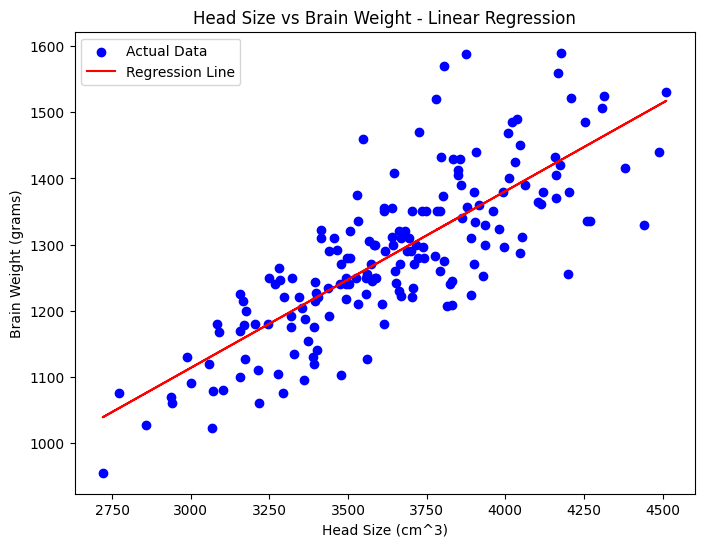

In [11]:
import numpy as np
import matplotlib.pyplot as plt

num = np.sum((X_train - x_mean)*(Y_train - y_mean))
den = np.sum((X_train - x_mean)**2)
b1 = num/den
print(b1)

b0 = y_mean - (b1 * x_mean)
print(b0)

Y_pred = b0 +b1*X_train
print(Y_pred)

plt.figure(figsize=(8,6))
plt.scatter(X_train, Y_train, color="blue", label="Actual Data")
plt.plot(X_train, Y_pred, color="red", label="Regression Line")
plt.xlabel("Head Size (cm^3)")
plt.ylabel("Brain Weight (grams)")
plt.title("Head Size vs Brain Weight - Linear Regression")
plt.legend()
plt.show()

In [20]:
#9.	Calculate and print the Root Mean Square Error (RMSE) for the predictions.
rmse = np.sqrt(np.mean((Y_train - Y_pred)**2))
print("Root mean Square Error:",rmse)

72.91544830431062


In [16]:
# 10.	Calculate the R-squared (R²) value to determine the proportion of variance explained by the model.
ss_res = np.sum((Y_train - Y_pred) ** 2)

ss_tot = np.sum((Y_train - np.mean(Y_train)) ** 2)

r2 = 1 - (ss_res / ss_tot)
print("R-squared (R²) value:", r2)


R-squared (R²) value: 0.6302549373879847


In [27]:
#11.	Train a linear regression model using inbuilt function using train set.
from sklearn.linear_model import LinearRegression

train = df.sample(frac=0.75, random_state=42)
test = df.drop(train.index)

X_train = train[["Head Size(cm^3)"]]  # X must be 2D for sklearn
Y_train = train["Brain Weight(grams)"]

model = LinearRegression()
model.fit(X_train, Y_train)

print("Intercept (b0):", model.intercept_)
print("Slope (b1):", model.coef_[0])

Intercept (b0): 346.15750182871545
Slope (b1): 0.2587488715240496


In [35]:
#2.	Predict the income for the test dataset using the trained model.
train = df.sample(frac=0.75, random_state=42)
test = df.drop(train.index)

X_train = train[["Head Size(cm^3)"]]
Y_train = train["Brain Weight(grams)"]

X_test = test[["Head Size(cm^3)"]]
Y_test = test["Brain Weight(grams)"]

model = LinearRegression()
model.fit(X_train, Y_train)

Y_pred_test = model.predict(X_test)
z = pd.DataFrame(Y_pred_test)
print(z)

              0
0   1313.360784
1   1434.972753
2   1337.683178
3   1242.981091
4   1349.585626
5   1393.055436
6   1315.948272
7   1288.262143
8   1352.949361
9   1451.015183
10  1384.257974
11  1424.105301
12  1364.334311
13  1295.507111
14  1446.616452
15  1344.410648
16  1412.461601
17  1335.613187
18  1227.456158
19  1253.331045
20  1293.695869
21  1246.086077
22  1349.068128
23  1293.437120
24  1389.432952
25  1225.644916
26  1274.807202
27  1432.902762
28  1272.995960
29  1294.730865
30  1260.058516
31  1085.403028
32  1145.691515
33  1205.980002
34  1305.339569
35  1140.775286
36  1186.573837
37  1268.855978
38  1281.534672
39  1260.317265
40  1140.257789
41  1224.351172
42  1304.304573
43  1214.001217
44  1122.404116
45  1063.668123
46  1137.411551
47  1194.077554
48  1342.599406
49  1379.859244
50  1204.686258
51  1106.102937
52  1274.030955
53  1166.391425
54  1313.878281
55  1246.344826
56  1178.811370
57  1224.351172
58  1223.574925


In [36]:
#3.	Calculate the RMSE and R-squared score for the predictions.
from sklearn.metrics import mean_squared_error, r2_score

rmse_test = np.sqrt(mean_squared_error(Y_test, Y_pred_test))
r2_test = r2_score(Y_test, Y_pred_test)

print("Test RMSE:", rmse_test)
print("Test R²:", r2_test)

Test RMSE: 74.35323941033008
Test R²: 0.6346832894965154


In [40]:
#4.	Compare both outcomes from without inbuilt function (section 1) and using inbuilt function.
print("\nComparison:")
print("Self made: RMSE =", rmse, ", R^2 =", r2)
print("Inbuit function: RMSE =", rmse_test, ", R^2 =", r2_test)


Comparison:
Self made: RMSE = 72.91544830431062 , R^2 = 0.6302549373879847
Inbuit function: RMSE = 74.35323941033008 , R^2 = 0.6346832894965154
